In [1]:
# New version of the LQG simulation script

import numpy as np
from LQG_controller import compute_finite_horizon_lqr_gains, finite_horizon_kalman_gains
from simulate_lqg import simulate_lqg, simulate_robust_lqg
from sdp_solver import solve_sdp
from simulation_plots import simulate_and_plot_average_trajectories


# --- Parameters ---
time_horizon = 30.0  # Total time 

dt = 1.0   # Time step
T = int(time_horizon / dt)  # Number of steps 

# System dimensions
n = 1  # Number of states, to chnage if needed !!
m = 1  # Number of control inputs

# --- System Matrices ---
theta = np.diag([0.90])  #mean reversion coefficient for each state, to adapt if needed !! try something bigger than 0.15 
A = np.eye(n) - theta * dt     # Dynamics matrix (n x n)
B = -dt * np.ones((n, m))      # Control input matrix (n x m)
C = np.eye(n)               # Measurement matrix (p x n) (measures first state)

# --- Initial State and Noise Covariances ---
mu = np.array([[130.0]]) 		        # To adapt if needed !! Multiple dimensions possible !	
sigma_x0 = 2.0                     		# Initial state uncertainty
X0_hat = sigma_x0**2 * np.eye(n)   		# Initial state covariance (n x n)
sigma_w = 2.0                      		# Process noise intensity
W_hat = sigma_w**2 * dt * np.eye(n) 	# Process noise covariance (n x n)
sigma_v = 2.0                       	# Measurement noise intensity
V_hat = sigma_v**2 * np.eye(n)      	# Measurement noise covariance (p x p) 

# --- Cost Matrices ---
Q = 4 * np.eye(n)  # State cost (penalize state deviations)
R = 2 * np.eye(m)  # Control cost (penalize large inputs)

# --- Compute Nominal LQR and Kalman Gains ---
K_list = compute_finite_horizon_lqr_gains(A, B, Q, R, T=T)         # LQR gain (m x n)
L_list = finite_horizon_kalman_gains(A, C, W_hat, V_hat, X0_hat, T)

# --- Solve SDP for Robust Covariances ---
sdp_result = solve_sdp(A, B, C, X0_hat, W_hat, V_hat, dt, T, rho_x0=10.0, rho_w=10.0, rho_v=10.0)
X0_robust = sdp_result["X0"]  # Robust initial covariance (n x n)
W0_robust = sdp_result["W0"]  # Robust process noise covariance (n x n)
V0_robust = sdp_result["V0"]  # Robust measurement noise covariance (p x p)


# print("SDP status:", sdp_result["status"])
# print("\nOptimal value:", sdp_result["optimal_value"])
# print("X0_robust:\n", X0_robust)
# print("W0_robust:\n", W0_robust)  # list of matrices
# print("V0_robust:\n", V0_robust) 


# --- Compute Robust Kalman Gain ---
L_rob = finite_horizon_kalman_gains(A, C, W0_robust, V0_robust, X0_robust, T) 


print(f"System dimensions: n={A.shape[0]}, p={C.shape[0]}")
print(f"First Kalman gain shape: {L_list[0].shape}")

System dimensions: n=1, p=1
First Kalman gain shape: (1, 1)


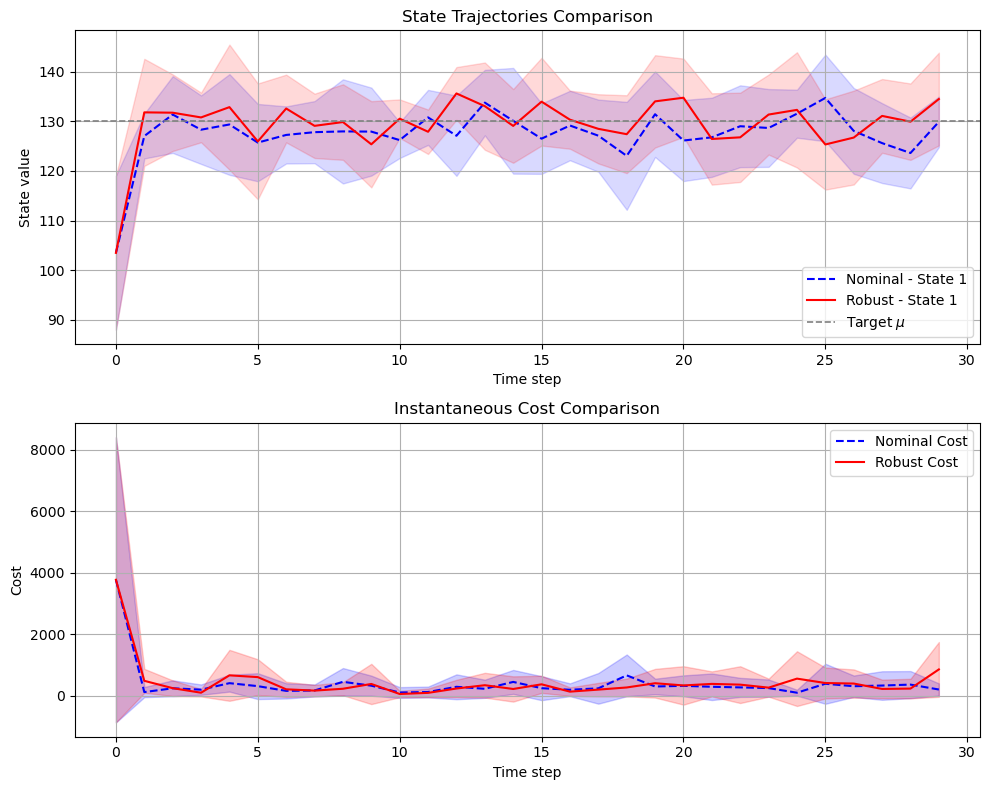

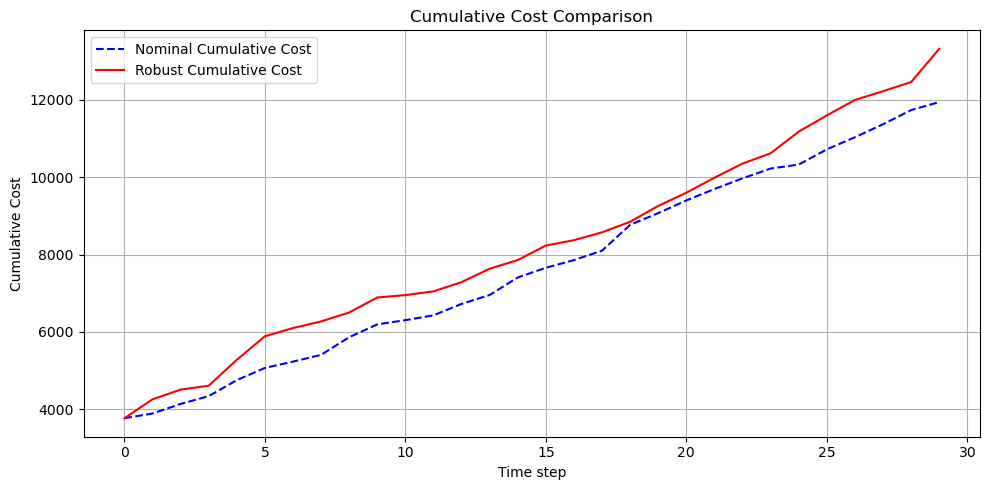

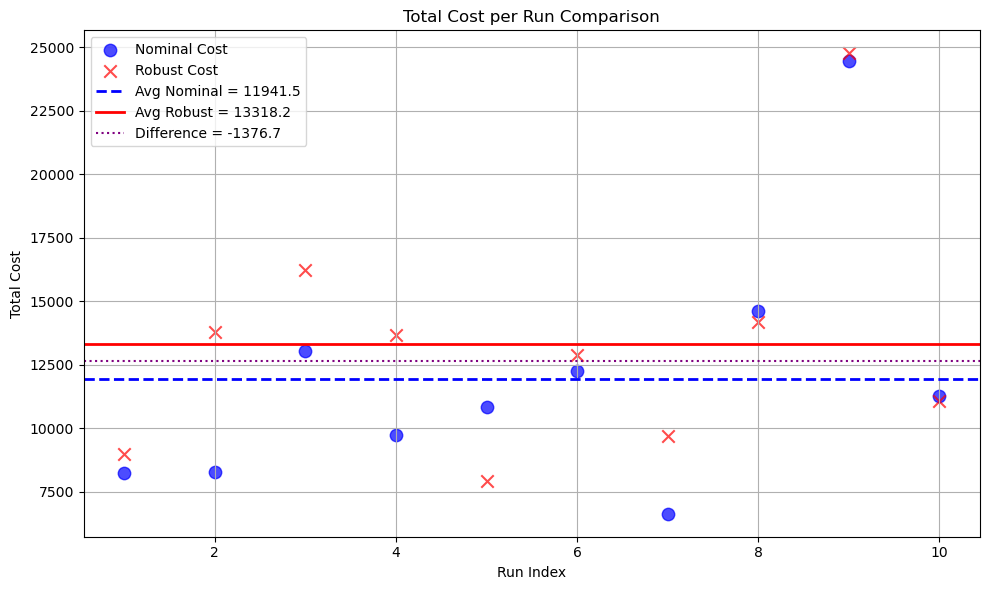


=== FINAL COST COMPARISON ===
Average Total Cost - Nominal: 11941.47
Average Total Cost - Robust:  13318.16
Cost Difference: -1376.69

=== Final Results ===
Nominal Controller Average Cost: 11941.46909450479
Robust Controller Average Cost: 13318.164038185036
Robustness Benefit: -1376.694943680246


In [ ]:
# --- Test noise levels ---
noise_factor = 0.5  # Change this to test different noise levels
W_real = [noise_factor * W for W in W0_robust]
V_real = [noise_factor * V for V in V0_robust]

x_nom_avg, x_rob_avg, avg_cost_nom, avg_cost_rob = simulate_and_plot_average_trajectories(
    T, A, B, C, mu,
    K_list, L_list,
    K_list_rob=K_list,     
    L_list_rob=L_rob,
    X0_robust=X0_robust,
    W_test=W_real,
    V_test=V_real,
    initial_point=0.80 * mu,
    N_runs=10,
    Q=Q,
    R=R
)
